# 03 · MDP, ecuación de Bellman y value iteration
**Entornos:** MiniDespacho (diminuto) · **Tiempo de ejecución:** ≤ 2 min en CPU · **Criterio de la lección:** residuo de Bellman < 1e-9, el valor $V^*$ coincide con la
simulación (≤ 3 errores estándar) y la política óptima le gana a `GreedyDespacho` (LB > 0), con n = 2000 episodios.

## 1. La idea en una frase
Si conocemos el modelo (qué pasa después de cada acción y con qué probabilidad), la mejor política se **calcula**, no se aprende: es un punto fijo de la ecuación de Bellman.

**En el sistema de Luca:** el valor de un estado es lo que el crítico de PPO intenta aproximar; aquí lo calculamos exacto para entender qué aproxima.
**En un problema de negocio:** el valor de "dos camiones libres y un pedido con holgura 2" es el costo esperado futuro óptimo desde ahí.

## 2. La intuición y la fórmula
Un MDP tiene estados $s$, acciones $a$, transiciones $P(s' \mid s,a)$ y recompensas $R(s,a)$. El valor óptimo de un estado es la mejor recompensa esperada acumulada:

$$V^*(s) = \max_{a \in \text{legales}(s)} \Bigl[\, R(s,a) + \gamma \sum_{s'} P(s' \mid s, a)\, V^*(s') \Bigr], \qquad V^*(\text{terminal}) = 0.$$

**Value iteration** aplica esa igualdad como asignación, una y otra vez, hasta que $V$ deja de cambiar. Con $\gamma = 1$ y horizonte finito converge
exactamente. La política óptima es el $\arg\max$. Aquí los "valores" son negativos porque son **costos** ($-$distancia $-$atraso).

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace
from rlf.core import EVAL_SEED_BASE, seed_everything
from rlf.eval.stats import mean_ci, paired_diff_ci, passes_lower
from rlf.envs.despacho import DespachoConfig, DespachoEnv, build_mdp
from rlf.agents.baselines import GreedyDespacho
from rlf.agents.tabular import value_iteration
from rlf.eval.arena import evaluate_policy
TRAIN_SEED = int(os.environ.get("RLF_TRAIN_SEED", "0"))
seed_everything(TRAIN_SEED)

## 3. El núcleo: el MDP explícito y value iteration inline
`build_mdp` enumera todos los estados alcanzables de "diminuto" (3×1 celdas, 2 camiones, 1 ranura de pedido, horizonte 6) con la esperanza exacta sobre las llegadas.

In [2]:
cfg = DespachoConfig.from_size("diminuto")
mdp = build_mdp(cfg)
nS, nA = mdp.legal.shape
print(f"estados: {nS} ({mdp.terminal.sum()} terminales), transiciones no nulas: {len(mdp.src)}, acciones: {nA}")
print("estado inicial (sin pedido) :", mdp.keys[int(np.flatnonzero(mdp.p0)[0])], "  formato (t, pedidos, camiones)")

def value_iteration_inline(mdp, gamma=1.0, tol=1e-10):
    """Value iteration escrito a mano. Devuelve V y la lista de cambios máximos por barrida."""
    nS, nA = mdp.legal.shape
    V = np.zeros(nS)
    deltas = []
    while True:
        # E[V(s')] para cada (s, a): suma de prob * V[dst] agrupada por (src, act)
        EV = np.zeros((nS, nA))
        np.add.at(EV, (mdp.src, mdp.act), mdp.prob * V[mdp.dst])
        Q = np.where(mdp.legal, mdp.R + gamma * EV, -np.inf)       # Bellman: R + γ E[V]
        V_new = np.where(mdp.terminal, 0.0, Q.max(1))              # máx sobre acciones legales
        deltas.append(np.abs(V_new - V).max())
        V = V_new
        if deltas[-1] < tol:
            return V, deltas

V_inline, deltas = value_iteration_inline(mdp)
V, Q, policy = value_iteration(mdp, gamma=1.0)
assert np.abs(V - V_inline).max() < 1e-9, "la versión inline y la de rlf deben coincidir"
v_star = float(mdp.p0 @ V)
print(f"barridas: {len(deltas)}   V* (valor esperado del estado inicial) = {v_star:.4f}   máx |V_inline − V_rlf| = {np.abs(V - V_inline).max():.1e}")

estados: 2427 (91 terminales), transiciones no nulas: 6020, acciones: 3
estado inicial (sin pedido) : (0, (None,), ((0, 0, 2, 0), (0, 0, 2, 0)))   formato (t, pedidos, camiones)
barridas: 11   V* (valor esperado del estado inicial) = -4.2049   máx |V_inline − V_rlf| = 0.0e+00


## 4. Resolver y graficar la convergencia
Cambio máximo de $V$ en cada barrida, y el retorno de la política óptima frente a `GreedyDespacho` en el entorno real (2000 episodios con semillas de evaluación).

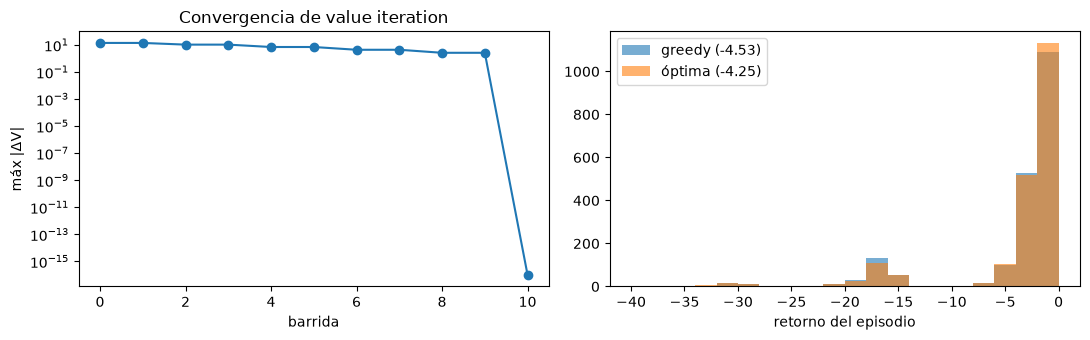

V* = -4.205   retorno simulado de la óptima = -4.252 ± 0.133 (EE)   greedy = -4.533


In [3]:
N = 2000
env_make = lambda: DespachoEnv.from_size("diminuto")


def optimal_returns(n):
    env = env_make(); out = np.zeros(n)
    for i in range(n):
        obs = env.reset(EVAL_SEED_BASE + i); done = False
        while not done:
            a_id = policy[mdp.index[env.state_key()]]
            st = env.step(int(np.flatnonzero(obs.option_ids == a_id)[0]))
            out[i] += st.rewards[0]; obs, done = st.obs, st.done
    return out

opt_ret = optimal_returns(N)
greedy_ret = evaluate_policy(env_make, GreedyDespacho(), N)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].semilogy(np.maximum(deltas, 1e-16), marker="o"); ax[0].set_xlabel("barrida"); ax[0].set_ylabel("máx |ΔV|"); ax[0].set_title("Convergencia de value iteration")
bins = np.arange(-40, 1, 2)
ax[1].hist(greedy_ret, bins, alpha=0.6, label=f"greedy ({greedy_ret.mean():.2f})"); ax[1].hist(opt_ret, bins, alpha=0.6, label=f"óptima ({opt_ret.mean():.2f})")
ax[1].set_xlabel("retorno del episodio"); ax[1].legend(); plt.tight_layout(); plt.show()
print(f"V* = {v_star:.3f}   retorno simulado de la óptima = {opt_ret.mean():.3f} ± {opt_ret.std(ddof=1)/np.sqrt(N):.3f} (EE)   greedy = {greedy_ret.mean():.3f}")

## 5. Experimentos "predice antes de correr"
### Experimento 1 · ¿Cuántas barridas necesita para converger con γ = 1 y horizonte 6?
**Predice:** ¿cerca de 6? ¿mucho más? ¿el error decae poco a poco o llega a cero de golpe?

In [4]:
print(f"barridas = {len(deltas)}; cambios: {np.round(deltas, 3)}")
assert 8 <= len(deltas) <= 14 and deltas[-1] == 0.0

barridas = 11; cambios: [14.    14.    10.5   10.5    7.     7.     4.375  4.375  2.615  2.615
  0.   ]


<details><summary>Respuesta esperada</summary>

Converge en 11 barridas (10 con cambio y una que confirma el cero). No decae poco a poco: el problema tiene horizonte finito, así que
cada barrida fija correctamente los estados a una decisión más del final, y tras la profundidad máxima del árbol de decisiones (≈ 10: hasta 6 esperas más asignaciones
en el mismo tick) el cambio es **exactamente 0**. Con horizonte infinito y $\gamma<1$ el error sí decaería geométricamente.
</details>

### Experimento 2 · ¿Cambia la política si `late_w` pasa de 2 a 0?
**Predice:** si el atraso no cuesta nada, ¿la política óptima cambia? ¿En muchos estados? (ojo: `U` se deriva de `late_w`, así que también baja).

In [5]:
mdp0 = build_mdp(replace(cfg, late_w=0.0))
V0, _, pol0 = value_iteration(mdp0)
common = [k for k in mdp.keys if k in mdp0.index and not mdp.terminal[mdp.index[k]]]
changed = [k for k in common if policy[mdp.index[k]] != pol0[mdp0.index[k]]]
print(f"estados comparables {len(common)}, con otra acción óptima: {len(changed)} ({100*len(changed)/len(common):.1f} %);  V*: {v_star:.3f} → {float(mdp0.p0 @ V0):.3f}")
assert len(changed) > 0 and float(mdp0.p0 @ V0) > v_star

estados comparables 2336, con otra acción óptima: 53 (2.3 %);  V*: -4.205 → -2.500


<details><summary>Respuesta esperada</summary>

Sí cambia, pero en pocos estados (53 de 2336, ≈ 2 %), y $V^*$ sube de ≈ −4,20 a ≈ −2,50. Sin costo por atraso, esperar a que un camión se libere deja de
penalizar y, además, dejar un pedido sin atender cuesta solo `U` = 2. Cambiar la función de costo cambia la política: la recompensa **es** el objetivo.
</details>

### Experimento 3 · ¿Cuánto vale esperar en el estado inicial?
**Predice:** si al inicio hay un pedido pendiente y dos camiones libres, ¿conviene asignar o esperar? ¿Cuánto peor es esperar?

In [6]:
rows = []
for i in np.flatnonzero(mdp.p0):
    key = mdp.keys[i]
    if key[1][0] is not None:
        rows.append((key[1][0], Q[i, 0], Q[i, 2]))       # id 0 = asignar al camión 0, id 2 = esperar
for order, q_assign, q_wait in rows:
    print(f"pedido (x,y,qty,holgura)={order}:  Q(asignar)={q_assign:7.3f}   Q(esperar)={q_wait:7.3f}")
assert len(rows) == 3 and all(qw < qa - 3 for _, qa, qw in rows)

pedido (x,y,qty,holgura)=(0, 0, 1, 2):  Q(asignar)= -5.058   Q(esperar)= -9.593
pedido (x,y,qty,holgura)=(1, 0, 1, 2):  Q(asignar)= -5.737   Q(esperar)=-10.315
pedido (x,y,qty,holgura)=(2, 0, 1, 2):  Q(asignar)= -6.741   Q(esperar)=-13.292


<details><summary>Respuesta esperada</summary>

Asignar siempre es mejor: esperar cuesta entre ≈ 4,5 y ≈ 6,6 unidades más (Q(esperar) ≈ −9,6 a −13,3 frente a −5,1 a −6,7 de asignar), porque el pedido vence
(holgura 2) y el atraso se paga a 2 por tick. Cuanto más lejos está el pedido, más caro se vuelve todo.
</details>

### Experimento 4 · ¿Qué estado alcanzable tiene el mayor valor absoluto?
**Predice:** el peor estado, ¿qué tiene de especial?

In [7]:
nt = ~mdp.terminal
worst = int(np.argmin(np.where(nt, V, 0.0)))
print("peor estado:", mdp.keys[worst], f"V = {V[worst]:.2f}")
t, pend, trucks = mdp.keys[worst]
assert V[worst] < -cfg.U and all(cap == 0 for (_, _, cap, _) in trucks) and pend[0] is not None

peor estado: (4, ((0, 0, 1, 2),), ((0, 0, 0, 0), (0, 0, 0, 0))) V = -21.00


<details><summary>Respuesta esperada</summary>

El peor estado alcanzable es t = 4 con un pedido pendiente y **los dos camiones sin capacidad** (cap = 0): ese pedido no se podrá atender
(−14) y, encima, cada llegada que falte también se rechazará (−14 con probabilidad ½), $V ≈ −21$. Los valores extremos salen de quedarse sin recursos, no de la distancia.
</details>

## 6. Criterio de la lección
n = 2000 episodios, γ = 1.

In [8]:
EV = np.zeros_like(Q); np.add.at(EV, (mdp.src, mdp.act), mdp.prob * V[mdp.dst])
resid = np.abs(np.where(mdp.legal, Q - (mdp.R + EV), 0.0)).max()
ok_a = resid < 1e-9                                                # (a) chequeo determinista
se = opt_ret.std(ddof=1) / np.sqrt(N)
ok_b = abs(opt_ret.mean() - v_star) <= 3 * se                       # (b) consistencia estadística
diff = paired_diff_ci(opt_ret, greedy_ret)
ok_c = diff.n == N and passes_lower(diff, 1e-12)                    # (c) óptima − greedy, LB > 0
print(f"{'afirmación':62s} resultado")
print(f"{'(a) residuo de Bellman %.1e < 1e-9' % resid:62s} {ok_a}")
print(f"{'(b) |simulado − V*| = %.3f ≤ 3 EE = %.3f' % (abs(opt_ret.mean() - v_star), 3 * se):62s} {ok_b}")
print(f"{'(c) óptima − greedy = %.3f  IC95 [%.3f, %.3f]' % (diff.mean, diff.lo, diff.hi):62s} {ok_c}")
assert ok_a and ok_b and ok_c

afirmación                                                     resultado
(a) residuo de Bellman 0.0e+00 < 1e-9                          True
(b) |simulado − V*| = 0.047 ≤ 3 EE = 0.398                     True
(c) óptima − greedy = 0.281  IC95 [0.198, 0.365]               True


## 7. Resumen y puente a la lección siguiente
- Con el modelo conocido, value iteration da la política **óptima** y $V^*$ exacto; la simulación lo confirma.
- La política óptima le gana a la heurística greedy, y ese valor $V^*$ es la vara para medir a los agentes que **aprenden sin el modelo**.
- **Lección 4:** quitamos el modelo. Q-learning tabular aprende la misma política solo interactuando con el entorno; medimos qué tan cerca llega de $V^*$.